# The cost of portfolio customization
### WRDS / CRSP walk-forward research | Josh Gutierrez

How much tracking risk should a portfolio manager accept to accommodate account
restrictions and avoid unnecessary trading?

This study uses **CRSP daily total returns retrieved directly from WRDS**. It
follows ten hypothetical constrained accounts across 2014–2025, with historical
risk estimation, monthly execution, drifting holdings and self-financed trading
costs. The accounts and policy allocation are assumptions; the market observations
are not simulated.

The comparison is about preserving a model's exposures. It is not a return forecast
or a claim that customization produces alpha. Development used AI coding assistance.

## 1. Reproduction and data provenance

Install `requirements.txt`. With a licensed WRDS account and local PostgreSQL
password file, run `python wrds_data.py --download`. Credentials never belong in
this notebook. See [data access and validation](docs/DATA.md).

The first complete run performs the main study plus eight pre-specified sensitivity
reruns. Subsequent notebook runs can reuse verified artifacts. Set `RECOMPUTE=True`
to rerun the study. There is no Yahoo or synthetic-data fallback.

In [1]:
from pathlib import Path
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image
from portfolio_engine import TARGET, CURRENT, TICKERS, example_clients
from wrds_data import load_wrds
from walkforward import StudyConfig
from run_research import execute, code_hashes

RECOMPUTE = False
OUT = Path("outputs/wrds")
returns, raw, provenance = load_wrds()
receipt_path = OUT / "run_summary.json"
receipt = json.loads(receipt_path.read_text()) if receipt_path.exists() else None
reusable = (receipt is not None and receipt["code_sha256"] == code_hashes()
            and receipt["config"] == asdict(StudyConfig())
            and len(receipt["sensitivity_specifications"]) == 8)
if reusable:
    quality = json.loads((OUT / "data_quality.json").read_text())
    reusable = quality["local_source_file_sha256"] == provenance["files"]
if RECOMPUTE or not reusable:
    receipt = execute(include_sensitivity=True)
quality = json.loads((OUT / "data_quality.json").read_text())
summary = pd.read_csv(OUT / "scenario_summary.csv")
annual = pd.read_csv(OUT / "annual_summary.csv")
sensitivity = pd.read_csv(OUT / "sensitivity_summary.csv")
intervals = pd.read_csv(OUT / "tracking_risk_intervals.csv")
display(Markdown(f"**Source:** {quality['source']}  \n**Retrieved:** {quality['retrieved_utc']}  \n**Rows:** {quality['security_day_rows']:,}; **trading days:** {quality['trading_days']:,}; **ETFs:** {quality['assets']}"))
display(pd.DataFrame([{
    "Start": quality["requested_start"], "End": quality["requested_end"],
    "Missing returns": quality["missing_returns"],
    "Duplicate security/date rows": quality["duplicate_security_dates"],
    "Return field": quality["return_field"],
}]))

**Source:** WRDS / CRSP US Stock Database, CIZ (Flat File Format 2.0)  
**Retrieved:** 2026-09-30T20:12:49.822175+00:00  
**Rows:** 32,192; **trading days:** 4,024; **ETFs:** 8

,Start,End,Missing returns,Duplicate security/date rows,Return field
0,2010-01-04,2025-12-31,0,0,dlyret


CRSP's CIZ `dlyret` includes distributions and delisting returns. We do not use
price changes as a substitute, and we do not add legacy delisting returns twice.
Historical names resolve tickers to permanent identifiers at the 2010 sample start.
The CIZ exchange calendar checks every expected security/day observation.

The extract is the **current database vintage**, not a historical archive of
what had been published at each decision date. The eight-ETF universe was chosen
retrospectively and held fixed. The experiment is not a survivorship-free security
selection study. Raw licensed rows and detailed daily simulations remain local.

## 2. The model and account restrictions

The model is a transparent multi-asset allocation, not an optimized hindsight
portfolio. All methods start from the same legacy account. SHY is a short-duration
Treasury ETF, **not cash**. A retained-weight floor does not prohibit sales of
particular shares or tax lots.

In [2]:
display(pd.DataFrame({"Model weight %": TARGET*100, "Starting account %": CURRENT*100}))
display(pd.DataFrame([{
    "Scenario": c.name, "Exclusions": ", ".join(c.blocked) or "None",
    "Floors": ", ".join(f"{k} {v:.0%}" for k,v in c.floors.items()) or "None",
    "Caps": ", ".join(f"{k} {v:.0%}" for k,v in c.caps.items()) or "None",
} for c in example_clients()]))

,Model weight %,Starting account %
SPY,30.0,40.0
IWM,10.0,15.0
EFA,15.0,10.0
EEM,5.0,5.0
IEF,20.0,10.0
TLT,5.0,5.0
GLD,10.0,10.0
SHY,5.0,5.0


,Scenario,Exclusions,Floors,Caps
0,Unrestricted,None,None,None
1,No gold,GLD,None,None
2,No emerging markets,EEM,None,None
3,No long Treasuries,TLT,None,None
4,10% short Treasuries,None,SHY 10%,None
5,20% short Treasuries,None,SHY 20%,None
6,Retain 40% US large cap,None,SPY 40%,None
7,20% US small-cap floor,None,IWM 20%,None
8,20% position cap,None,None,"SPY 20%, IWM 20%, EFA 20%, EEM 20%, IEF 20%, T..."
9,Domestic and liquid,"EFA, EEM",SHY 15%,None


## 3. Decision timing, optimization and funding

**Signal:** the final trading close of the previous month. Estimate annualized
Ledoit–Wolf covariance from the trailing 756 returns; use that close's account
weights. **Execution:** the next trading close. Old holdings earn that day's return
before the planned allocation is executed. Later returns accrue to the new holdings.
There is no implicit daily rebalancing.

For model weights $b$, proposed weights $w$ and lagged covariance $\hat\Sigma$:

$$\min_w (w-b)^\top\hat\Sigma(w-b), \quad 1^\top w=1,\quad l\leq w\leq u.$$

The lower-turnover method minimizes $\|w-w_{signal}\|_1$ subject to those bounds
and annualized TE no more than **25 bp above the minimum feasible TE**.
The proportional baseline faces the same constraints but uses no covariance.

Trading costs are **5 bp per dollar bought or sold**. For pre-trade sleeve values
$h$, total wealth $V$, cost rate $c$, and post-cost wealth $A$, solve:

$$A+c\sum_i|Aw_i-h_i|=V.$$

This funds costs inside the portfolio. Constraints apply to post-cost weights at
execution; intervening drift is measured. The policy benchmark has the same
monthly timing but is frictionless. Total-return sleeves allow fractional holdings
and reinvest distributions without tax or reinvestment costs. These are explicit
execution assumptions, not actual trade records.

[Full methodology](docs/METHODOLOGY.md) covers initial transitions, solver checks,
capacity diagnostics, cost sensitivity and limitations.

In [3]:
display(pd.DataFrame([{
    "Evaluation start": receipt["out_of_sample_start"],
    "Evaluation end": receipt["out_of_sample_end"],
    "Trading days": receipt["evaluation_days"],
    "Monthly execution dates": receipt["rebalance_dates"],
    "Portfolio paths": receipt["portfolio_paths"],
    "Validated allocation decisions": receipt["validated_allocation_decisions"],
    "Signals strictly precede execution": receipt["strict_signal_before_execution"],
}]))
assert receipt["strict_signal_before_execution"]
assert receipt["validated_allocation_decisions"] == len(summary)*receipt["rebalance_dates"]

,Evaluation start,Evaluation end,Trading days,Monthly execution dates,Portfolio paths,Validated allocation decisions,Signals strictly precede execution
0,2014-01-02,2025-12-31,3018,144,30,4320,True


## 4. Tracking risk versus turnover

Gross TE measures the volatility of daily portfolio returns minus the drifting
policy benchmark before each day's trading-cost debit. Net TE includes that debit.
A lower in-sample risk objective is not evidence of out-of-sample dominance.
Annualized turnover and costs below are measured from the actual simulated trades.

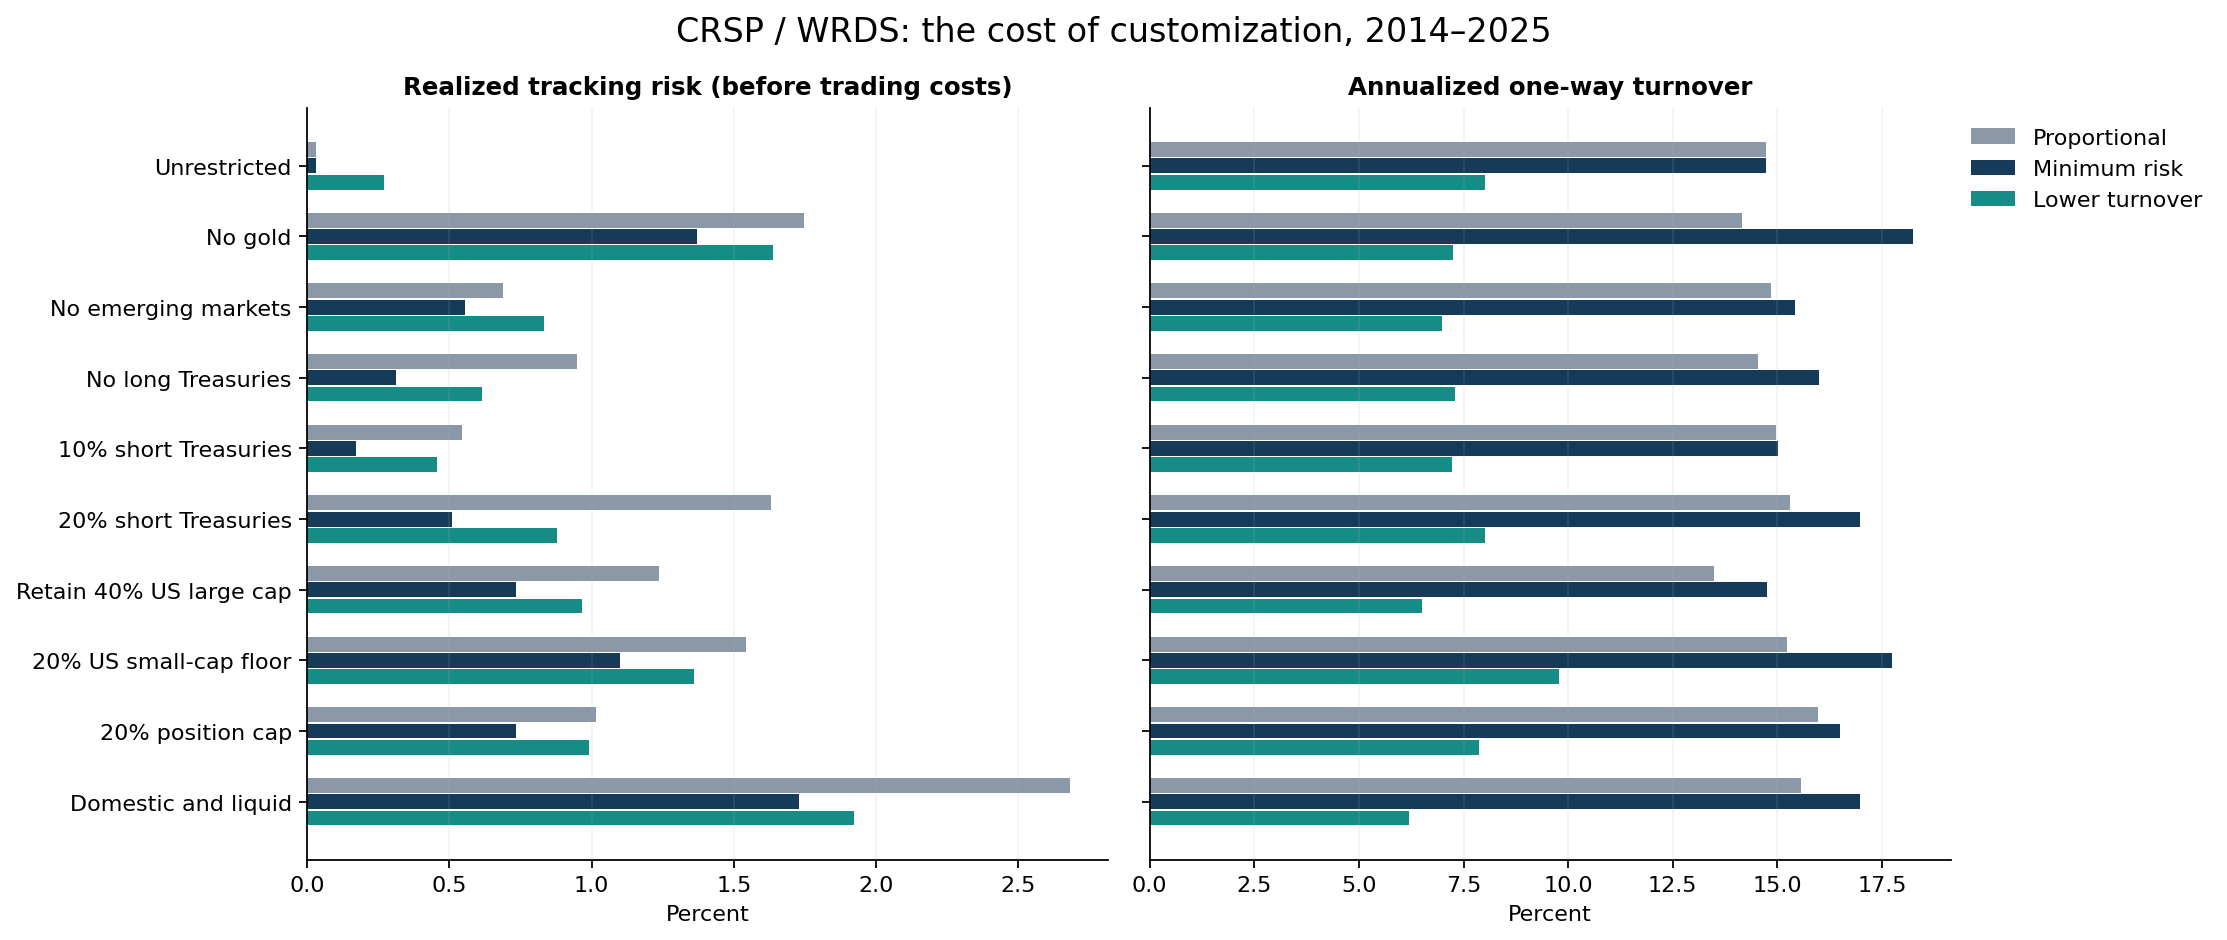

,client,method,gross_te_pct,net_te_pct,annual_one_way_turnover_pct,annual_incurred_cost_bps
0,Unrestricted,Proportional,0.029,0.034,14.736,1.474
1,Unrestricted,Minimum risk,0.029,0.034,14.736,1.474
2,Unrestricted,Lower turnover,0.269,0.269,8.018,0.802
3,No gold,Proportional,1.748,1.749,14.154,1.415
4,No gold,Minimum risk,1.369,1.370,18.231,1.823
5,No gold,Lower turnover,1.639,1.639,7.245,0.725
6,No emerging markets,Proportional,0.690,0.690,14.840,1.484
7,No emerging markets,Minimum risk,0.553,0.554,15.424,1.542
8,No emerging markets,Lower turnover,0.831,0.831,6.985,0.699
9,No long Treasuries,Proportional,0.948,0.948,14.549,1.455


In [4]:
display(Image(filename=str(OUT/"tracking_and_turnover.png")))
columns = ["client", "method", "gross_te_pct", "net_te_pct",
           "annual_one_way_turnover_pct", "annual_incurred_cost_bps"]
display(summary[columns].round(3))

## 5. One account: what does avoiding trades actually buy?

The no-gold account makes the trade-off concrete. Lower turnover can sound like a
large benefit, but its economic value depends on cost per dollar traded. In a liquid
ETF account, exposure risk can matter much more than the small dollar savings.
The following text is calculated from this run, not carried over from the old study.

For **No gold**, lower-turnover allocation reduces annual one-way turnover from **18.23% to 7.25%**. Realized gross TE changes from **1.37% to 1.64%** (+27.0 bp). At the base 5-bp trading-cost assumption, annualized modeled cost savings are **1.10 bp of portfolio value**. That cost saving alone does not establish that the extra tracking risk is worthwhile.

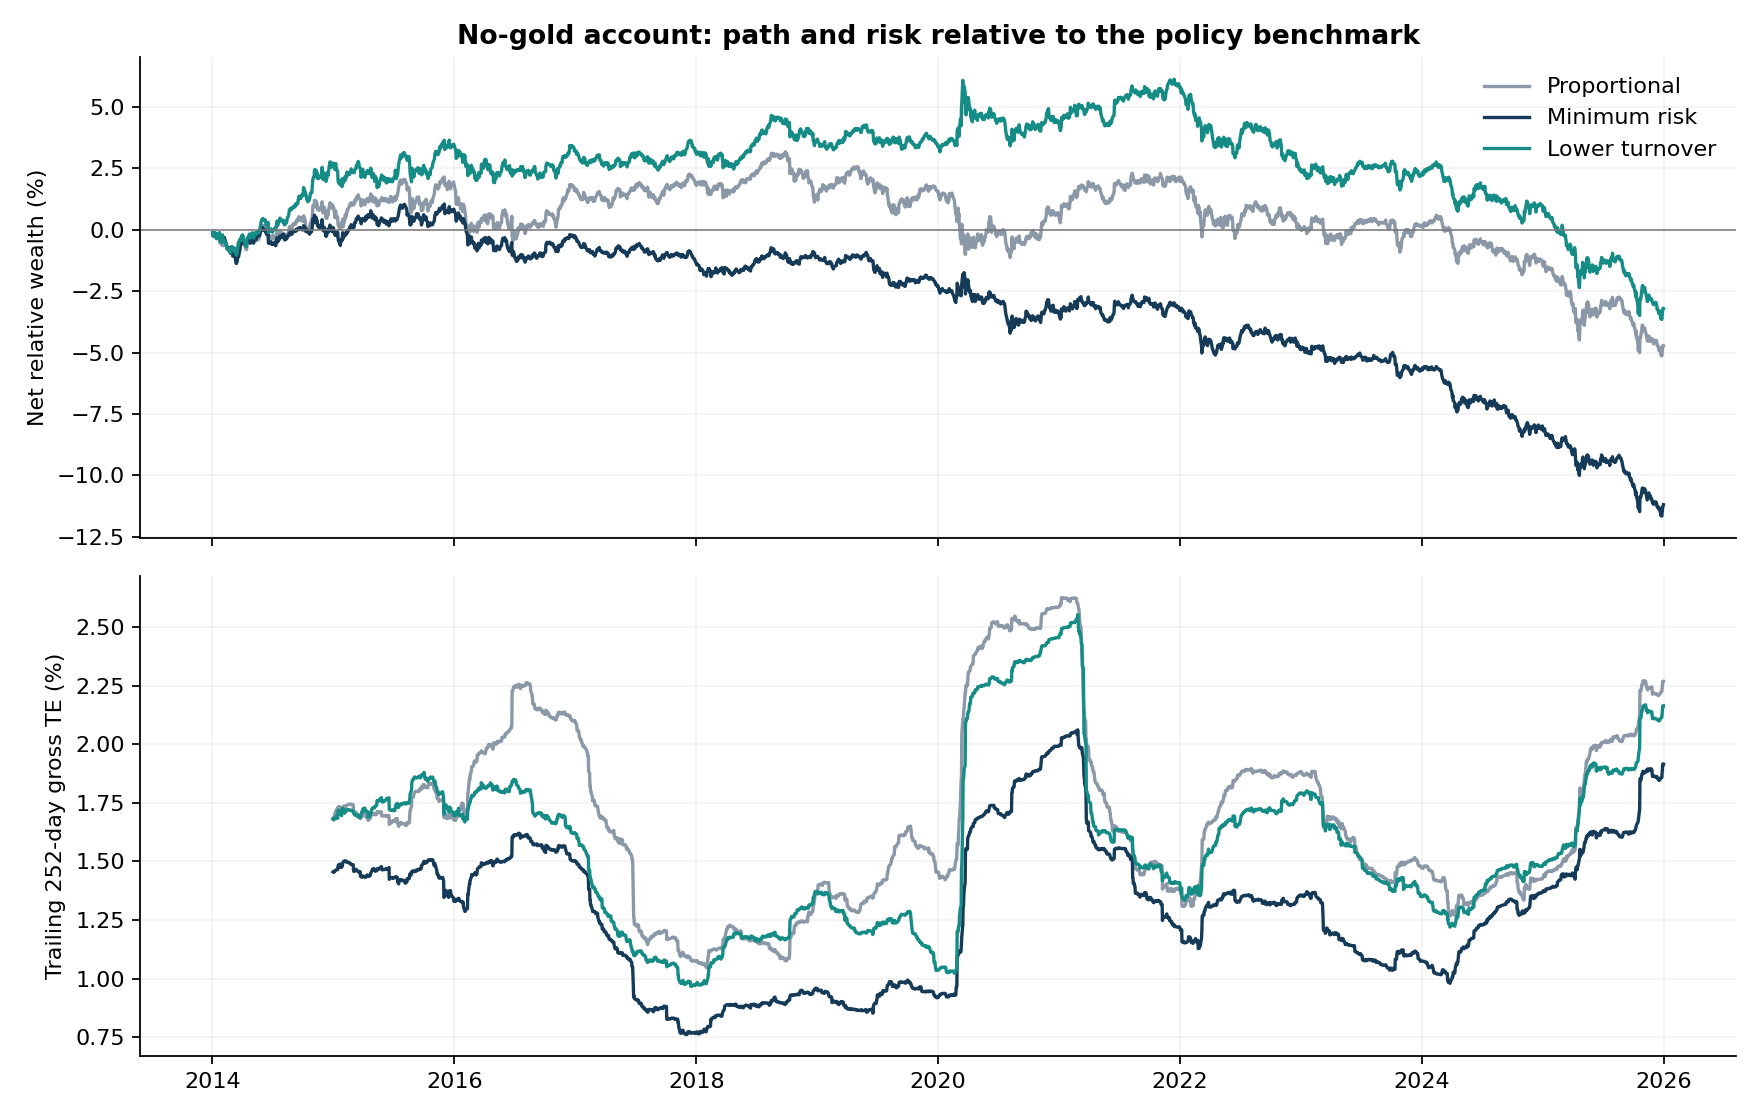

In [5]:
gold=summary.query("client == 'No gold'").set_index("method")
a,b=gold.loc["Minimum risk"],gold.loc["Lower turnover"]
saving=a.annual_incurred_cost_bps-b.annual_incurred_cost_bps
extra=(b.gross_te_pct-a.gross_te_pct)*100
display(Markdown(
    f"For **No gold**, lower-turnover allocation reduces annual one-way turnover "
    f"from **{a.annual_one_way_turnover_pct:.2f}% to {b.annual_one_way_turnover_pct:.2f}%**. "
    f"Realized gross TE changes from **{a.gross_te_pct:.2f}% to {b.gross_te_pct:.2f}%** "
    f"({extra:+.1f} bp). At the base 5-bp trading-cost assumption, annualized modeled "
    f"cost savings are **{saving:.2f} bp of portfolio value**. "
    "That cost saving alone does not establish that the extra tracking risk is worthwhile."
))
display(Image(filename=str(OUT/"no_gold_history.png")))

## 6. Regimes, uncertainty and sensitivity

A full-period average can conceal unstable correlations. Calendar-year results
expose that variation; the paired 21-day circular-block bootstrap describes sampling
uncertainty in the lower-turnover minus minimum-risk TE difference. It does not
validate a strategy or cover future regime changes.

Eight alternatives rerun the whole simulation on three illustrative restrictions:
252/504-day history; sample covariance; 0/50-bp risk allowance; and 1/10/25-bp trading
costs. The base case remains unchanged. Zero allowance recovers the unique
minimum-risk portfolio when covariance is positive definite.

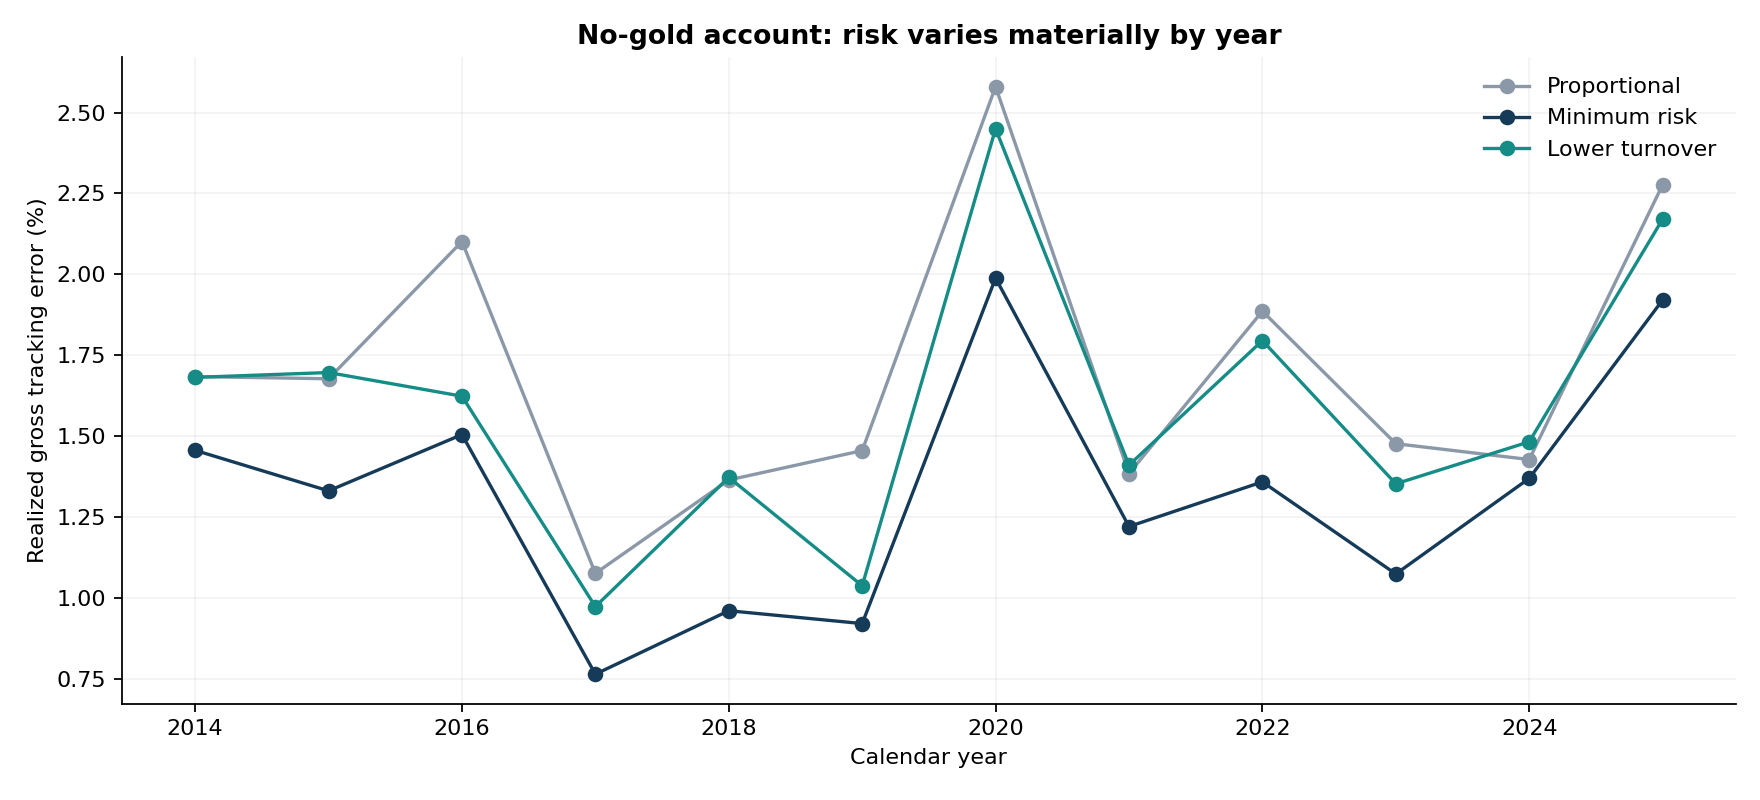

,client,gross_te_difference_pp,lower_95_pp,upper_95_pp,block_days,repetitions
0,10% short Treasuries,0.2841,0.2410,0.3393,21,1000
1,20% US small-cap floor,0.2601,0.2150,0.3039,21,1000
2,20% position cap,0.2592,0.1751,0.3604,21,1000
3,20% short Treasuries,0.3690,0.2961,0.4733,21,1000
4,Domestic and liquid,0.1920,0.1502,0.2367,21,1000
5,No emerging markets,0.2776,0.2390,0.3186,21,1000
6,No gold,0.2699,0.1996,0.3558,21,1000
7,No long Treasuries,0.3045,0.2631,0.3537,21,1000
8,Retain 40% US large cap,0.2347,0.2002,0.2698,21,1000
9,Unrestricted,0.2397,0.1985,0.2990,21,1000


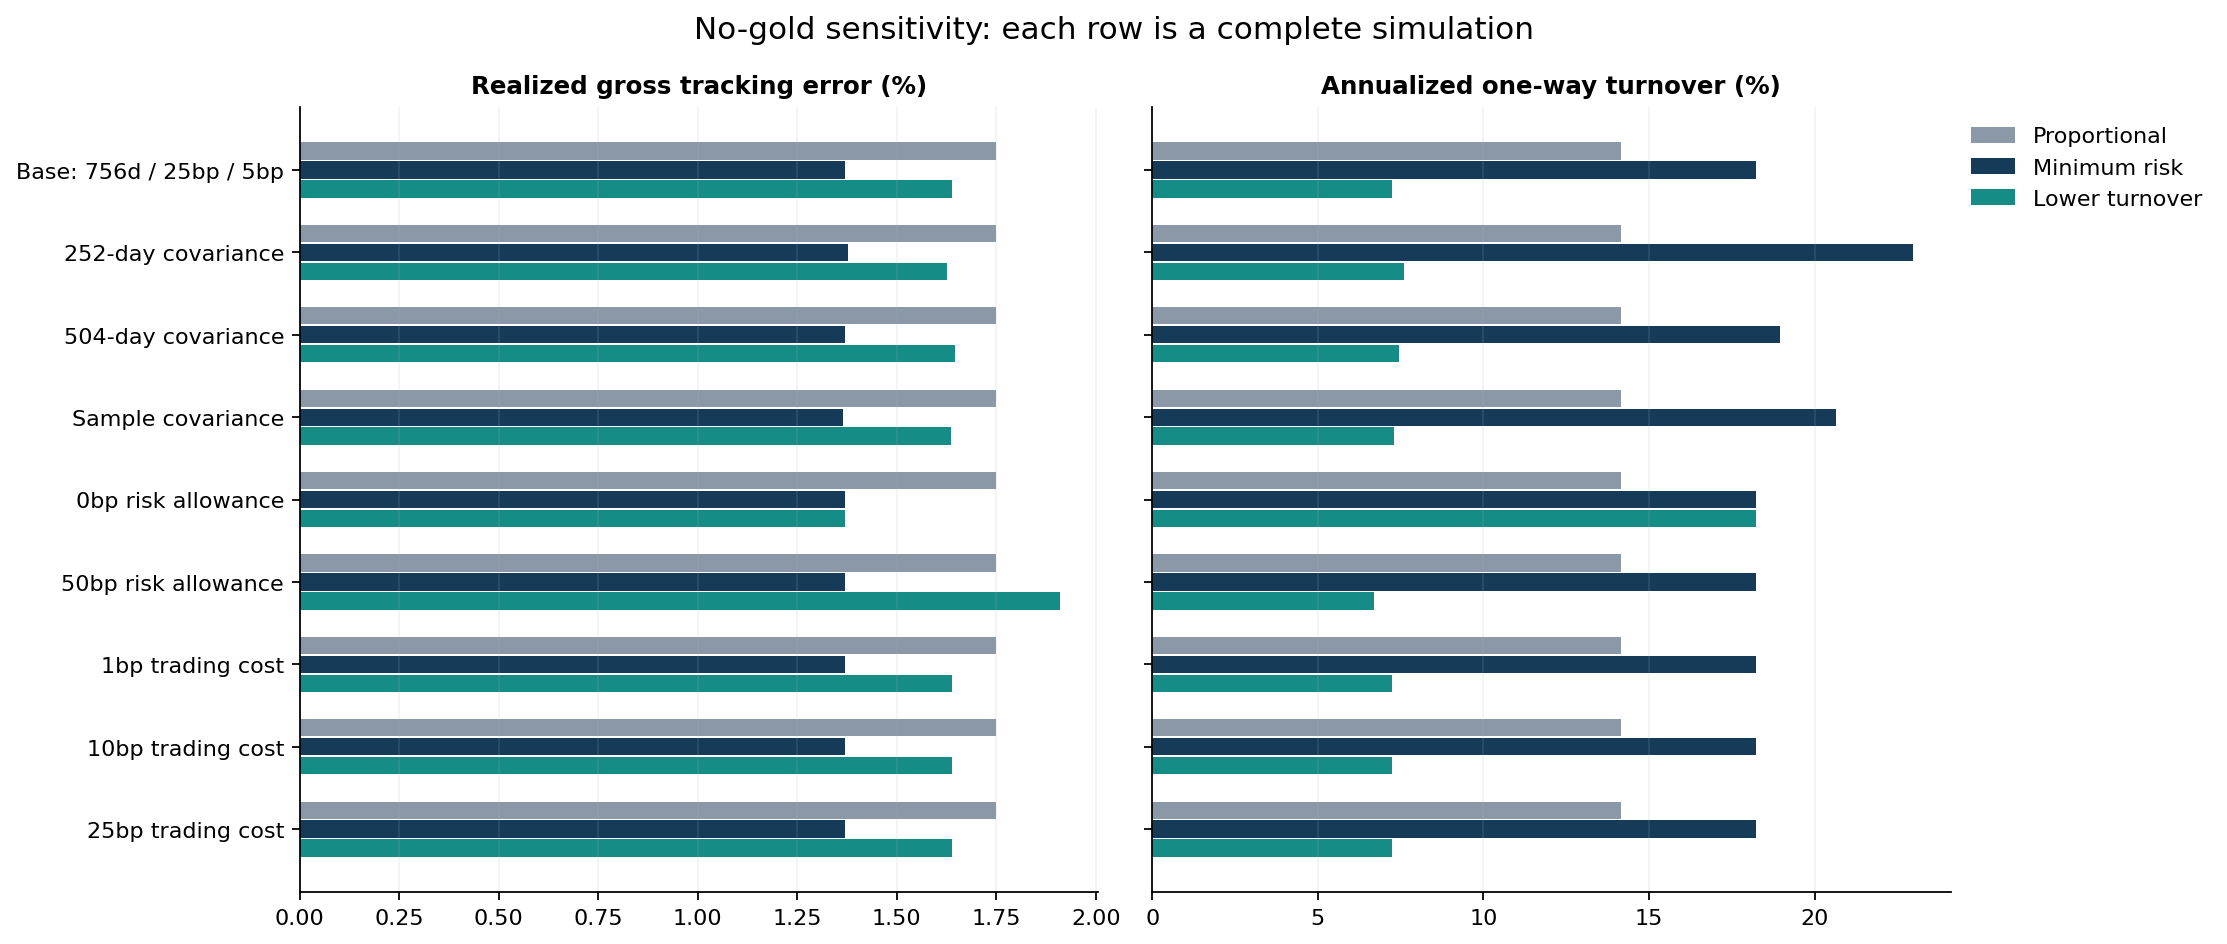

,specification,method,gross_te_pct,annual_one_way_turnover_pct,annual_incurred_cost_bps
0,Base: 756d / 25bp / 5bp,Proportional,1.748,14.154,1.415
1,Base: 756d / 25bp / 5bp,Minimum risk,1.369,18.231,1.823
2,Base: 756d / 25bp / 5bp,Lower turnover,1.639,7.245,0.725
9,252-day covariance,Proportional,1.748,14.154,1.415
10,252-day covariance,Minimum risk,1.377,22.955,2.296
11,252-day covariance,Lower turnover,1.626,7.593,0.759
18,504-day covariance,Proportional,1.748,14.154,1.415
19,504-day covariance,Minimum risk,1.369,18.943,1.894
20,504-day covariance,Lower turnover,1.645,7.448,0.745
27,Sample covariance,Proportional,1.748,14.154,1.415


In [6]:
display(Image(filename=str(OUT/"annual_risk.png")))
display(intervals.round(4))
display(Image(filename=str(OUT/"sensitivity.png")))
display(sensitivity.query("client == 'No gold'")[["specification", "method", "gross_te_pct",
    "annual_one_way_turnover_pct", "annual_incurred_cost_bps"]].round(3))
assert len(receipt["sensitivity_specifications"]) == 8

## 7. Net outcomes and implementation limits

These are simulated account outcomes, not a forecast or a ranking of investment
skill. A constraint changes exposures and can make a portfolio outperform or
underperform by chance. The frictionless benchmark and differing exposures mean
net CAGR alone is not the right criterion for choosing the implementation rule.

Monthly caps/floors can be crossed by intervening market moves. The drift metrics
make that visible; this is not a continuous-compliance engine. Trade participation
uses **lagged** 20-day CRSP price-times-volume. It is a capacity diagnostic, not a
market-impact model or proof of executable fills.

In [7]:
display(summary[["client", "method", "net_cagr_pct", "net_volatility_pct",
    "max_drawdown_pct", "days_weight_limits_drifted", "max_weight_limit_drift_pp"]].round(3))
display(Markdown(
    f"Largest nonzero simulated trade / lagged ADV20: "
    f"**{receipt['maximum_trade_to_lagged_adv20_pct']:.4f}%** at the $1m starting account size. "
    f"Trades missing the volume diagnostic: **{receipt['nonzero_trades_missing_adv20']}**."
))

,client,method,net_cagr_pct,net_volatility_pct,max_drawdown_pct,days_weight_limits_drifted,max_weight_limit_drift_pp
0,Unrestricted,Proportional,8.075,10.239,-21.910,0,0.000
1,Unrestricted,Minimum risk,8.075,10.239,-21.910,0,0.000
2,Unrestricted,Lower turnover,8.278,10.265,-21.877,0,0.000
3,No gold,Proportional,7.664,11.053,-23.207,0,0.000
4,No gold,Minimum risk,7.034,10.132,-22.828,0,0.000
5,No gold,Lower turnover,7.806,10.345,-23.464,0,0.000
6,No emerging markets,Proportional,8.212,9.948,-21.384,0,0.000
7,No emerging markets,Minimum risk,8.292,10.276,-21.648,0,0.000
8,No emerging markets,Lower turnover,8.861,10.384,-21.764,0,0.000
9,No long Treasuries,Proportional,8.374,10.788,-21.420,0,0.000


Largest nonzero simulated trade / lagged ADV20: **0.2490%** at the $1m starting account size. Trades missing the volume diagnostic: **0**.

## 8. What the evidence supports

This study measures the cost of adapting a fixed model to specified restrictions
using licensed historical returns and an explicit decision/execution clock. It
shows exposure risk, actual modeled turnover, funded cost debits, variation by
year and sensitivity to research assumptions.

It does **not** establish alpha, optimal client advice, stock-level direct indexing,
tax savings, market-impact calibration or production trading readiness. Historical
identity resolution and lagged decisions do not eliminate revised data or fixed-
universe selection bias. Hypothetical client restrictions cannot be relabeled as
real client data just because the returns come from WRDS.

**Review trail:** [data contract](docs/DATA.md), [methodology](docs/METHODOLOGY.md),
[source/quality receipt](outputs/wrds/data_quality.json),
[run receipt](outputs/wrds/run_summary.json), and the automated tests.

The original Yahoo/static study is superseded. Its files under `outputs/market/`
are preserved as historical artifacts, not presented as the current result.

In [8]:
assert provenance["source"].startswith("WRDS / CRSP")
assert quality["missing_returns"] == 0 and quality["duplicate_security_dates"] == 0
assert receipt["code_sha256"] == code_hashes()
print("Verified WRDS provenance, source hashes, chronology and complete sensitivity receipt.")
print("Source rows and detailed simulated holdings/trades are local-only; no credentials are in this notebook.")

Verified WRDS provenance, source hashes, chronology and complete sensitivity receipt.
Source rows and detailed simulated holdings/trades are local-only; no credentials are in this notebook.
